In [2]:
import pandas as pd

# Financial Analysis of Microsoft, Tesla and Apple (2023–2025)

## Project Overview

The objective of this analysis is to examine the financial performance 
of Microsoft, Tesla and Apple using their annual 10-K filings from 2023 
to 2025.

Using Python and Pandas, this analysis explores financial trends, 
year-over-year growth and key financial indicators.

## Dataset

The dataset contains the following financial metrics:

- Total Revenue
- Net Income
- Total Assets
- Total Liabilities
- Cash Flow from Operating Activities

All financial figures are reported in USD millions.

## Data Source

US Securities and Exchange Commission (SEC) EDGAR database.

In [4]:
import pandas as pd
from pathlib import Path

# Locate the CSV file inside the data folder
file_path = Path("data/financial_data.csv")

# Load the dataset
df = pd.read_csv(file_path)

# Display the first five rows
df.head()

,company,fiscal_period_end,year,revenue,net_income,total_assets,total_liabilities,ocf
0,microsoft,2023/06/30,2023,211915,72361,411976,205753,87582
1,microsoft,2024/06/30,2024,245122,88136,512163,243686,118548
2,microsoft,2025/06/30,2025,281724,101832,619003,275524,136162
3,tesla,2023/12/31,2023,96773,14974,106618,43009,13256
4,tesla,2024/12/31,2024,97690,7091,122070,48390,14923


In [5]:
# Check the size of the dataset
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate company-year records
print("\nDuplicate records:")
print(df.duplicated(subset=["company", "year"]).sum())

Dataset shape: (9, 8)
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   company            9 non-null      str  
 1   fiscal_period_end  9 non-null      str  
 2   year               9 non-null      int64
 3   revenue            9 non-null      int64
 4   net_income         9 non-null      int64
 5   total_assets       9 non-null      int64
 6   total_liabilities  9 non-null      int64
 7   ocf                9 non-null      int64
dtypes: int64(6), str(2)
memory usage: 708.0 bytes

Missing values:
company              0
fiscal_period_end    0
year                 0
revenue              0
net_income           0
total_assets         0
total_liabilities    0
ocf                  0
dtype: int64

Duplicate records:
0


In [6]:
# Convert fiscal period end into a date
df["fiscal_period_end"] = pd.to_datetime(df["fiscal_period_end"])

# Standardise company names
df["company"] = df["company"].str.strip().str.title()

# Sort by company and financial year
df = df.sort_values(
    by=["company", "year"]
).reset_index(drop=True)

df.head(9)

,company,fiscal_period_end,year,revenue,net_income,total_assets,total_liabilities,ocf
0,Apple,2023-09-30,2023,383285,96995,352583,290437,110543
1,Apple,2024-09-28,2024,391035,93736,364980,308030,118254
2,Apple,2025-09-27,2025,416161,112010,359241,285508,111482
3,Microsoft,2023-06-30,2023,211915,72361,411976,205753,87582
4,Microsoft,2024-06-30,2024,245122,88136,512163,243686,118548
5,Microsoft,2025-06-30,2025,281724,101832,619003,275524,136162
6,Tesla,2023-12-31,2023,96773,14974,106618,43009,13256
7,Tesla,2024-12-31,2024,97690,7091,122070,48390,14923
8,Tesla,2025-12-31,2025,94827,3855,137806,54941,14747


In [7]:
# Financial metrics to analyse
financial_metrics = [
    "revenue",
    "net_income",
    "total_assets",
    "total_liabilities",
    "ocf"
]

# Calculate year-over-year percentage changes
for metric in financial_metrics:
    df[f"{metric}_growth_pct"] = (
        df.groupby("company")[metric]
        .pct_change(fill_method=None) * 100
    )

# Display the results
growth_columns = [
    "company",
    "year",
    "revenue_growth_pct",
    "net_income_growth_pct",
    "total_assets_growth_pct",
    "total_liabilities_growth_pct",
    "ocf_growth_pct"
]

df[growth_columns].round(2)

,company,year,revenue_growth_pct,net_income_growth_pct,total_assets_growth_pct,total_liabilities_growth_pct,ocf_growth_pct
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.02,-3.36,3.52,6.06,6.98
2,Apple,2025,6.43,19.50,-1.57,-7.31,-5.73
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.67,21.80,24.32,18.44,35.36
5,Microsoft,2025,14.93,15.54,20.86,13.07,14.86
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.95,-52.64,14.49,12.51,12.58
8,Tesla,2025,-2.93,-45.64,12.89,13.54,-1.18


In [8]:
# Calculate financial ratios

# 1. Net Profit Margin (%)
df["net_profit_margin_pct"] = (
    df["net_income"] / df["revenue"] * 100
)

# 2. Operating Cash Flow Margin (%)
df["ocf_margin_pct"] = (
    df["ocf"] / df["revenue"] * 100
)

# 3. Liabilities-to-Assets Ratio (%)
df["liabilities_to_assets_pct"] = (
    df["total_liabilities"] / df["total_assets"] * 100
)

# 4. Cash Conversion Ratio
df["cash_conversion"] = (
    df["ocf"] / df["net_income"]
)

# 5. Shareholders' Equity (simplified)
df["equity"] = (
    df["total_assets"] - df["total_liabilities"]
)

# Display results
ratio_columns = [
    "company",
    "year",
    "net_profit_margin_pct",
    "ocf_margin_pct",
    "liabilities_to_assets_pct",
    "cash_conversion",
    "equity"
]

df[ratio_columns].round(2)

,company,year,net_profit_margin_pct,ocf_margin_pct,liabilities_to_assets_pct,cash_conversion,equity
0,Apple,2023,25.31,28.84,82.37,1.14,62146
1,Apple,2024,23.97,30.24,84.40,1.26,56950
2,Apple,2025,26.92,26.79,79.48,1.00,73733
3,Microsoft,2023,34.15,41.33,49.94,1.21,206223
4,Microsoft,2024,35.96,48.36,47.58,1.35,268477
5,Microsoft,2025,36.15,48.33,44.51,1.34,343479
6,Tesla,2023,15.47,13.70,40.34,0.89,63609
7,Tesla,2024,7.26,15.28,39.64,2.10,73680
8,Tesla,2025,4.07,15.55,39.87,3.83,82865


In [9]:
# Compare the companies in FY2025

latest_year = df["year"].max()

comparison = df[df["year"] == latest_year][[
    "company",
    "revenue",
    "net_income",
    "total_assets",
    "total_liabilities",
    "ocf",
    "net_profit_margin_pct",
    "liabilities_to_assets_pct"
]]

# Rank companies by revenue
comparison = comparison.sort_values(
    by="revenue",
    ascending=False
)

comparison.round(2)

,company,revenue,net_income,total_assets,total_liabilities,ocf,net_profit_margin_pct,liabilities_to_assets_pct
2,Apple,416161,112010,359241,285508,111482,26.92,79.48
5,Microsoft,281724,101832,619003,275524,136162,36.15,44.51
8,Tesla,94827,3855,137806,54941,14747,4.07,39.87


In [10]:
# Calculate average financial performance (2023–2025)

company_summary = df.groupby("company")[[
    "revenue",
    "net_income",
    "net_profit_margin_pct",
    "ocf"
]].mean()

company_summary.round(2)

,revenue,net_income,net_profit_margin_pct,ocf
company,,,,
Apple,396827.00,100913.67,25.40,113426.33
Microsoft,246253.67,87443.00,35.42,114097.33
Tesla,96430.00,8640.00,8.93,14308.67


In [11]:
# Calculate Compound Annual Growth Rate (CAGR)

def calculate_cagr(series):
    values = series.dropna()

    number_of_periods = len(values) - 1

    if number_of_periods <= 0 or values.iloc[0] <= 0:
        return float("nan")

    return (
        (values.iloc[-1] / values.iloc[0])
        ** (1 / number_of_periods) - 1
    ) * 100


# Calculate CAGR for revenue and net income
cagr_table = df.groupby("company")[
    ["revenue", "net_income"]
].agg(calculate_cagr)

cagr_table.columns = [
    "Revenue CAGR (%)",
    "Net Income CAGR (%)"
]

cagr_table.round(2)

,Revenue CAGR (%),Net Income CAGR (%)
company,,
Apple,4.20,7.46
Microsoft,15.30,18.63
Tesla,-1.01,-49.26


Matplotlib is building the font cache; this may take a moment.


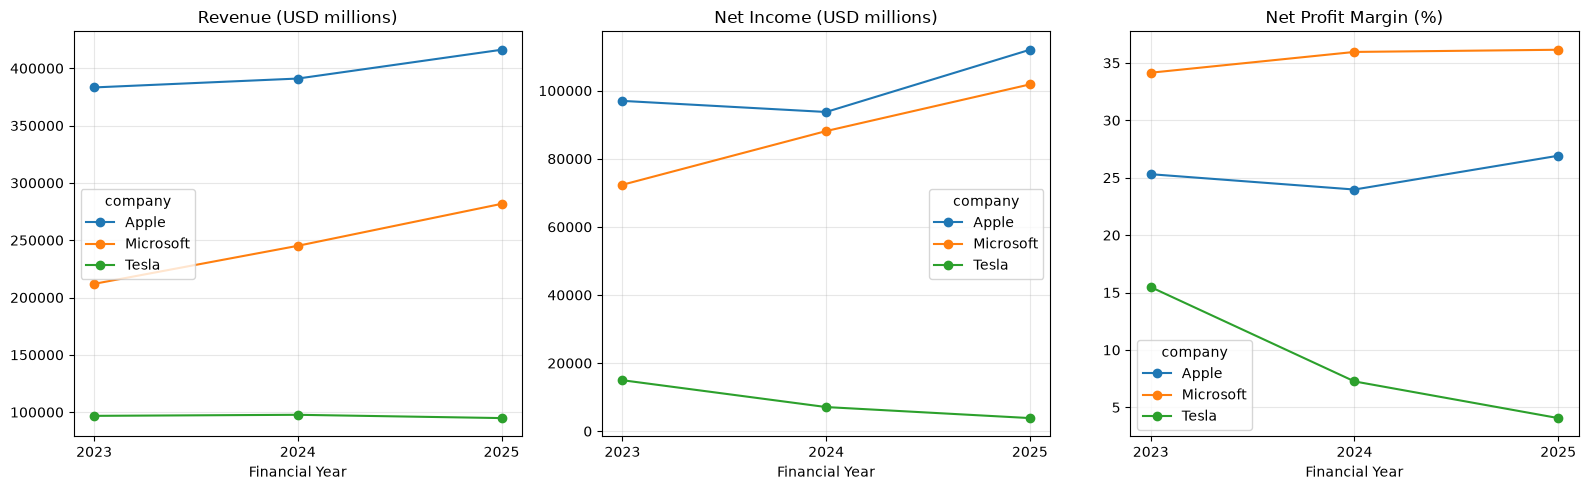

In [12]:
import matplotlib.pyplot as plt

# Create three financial trend charts

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

charts = [
    ("revenue", "Revenue (USD millions)"),
    ("net_income", "Net Income (USD millions)"),
    ("net_profit_margin_pct", "Net Profit Margin (%)")
]

for ax, (metric, title) in zip(axes, charts):

    pivot = df.pivot(
        index="year",
        columns="company",
        values=metric
    )

    pivot.plot(
        marker="o",
        ax=ax,
        title=title
    )

    ax.set_xticks([2023, 2024, 2025])
    ax.set_xlabel("Financial Year")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Financial Analysis Findings (2023–2025)

### 1. Revenue Performance

Apple recorded the highest revenue in FY2025 at USD 416.16 billion.

Microsoft demonstrated consistent revenue growth, with revenue increasing by 14.93% in FY2025.

Tesla experienced a decline in revenue of approximately 2.93% in FY2025 compared with the previous year.

### 2. Profitability

Microsoft recorded the highest net profit margin in FY2025 at approximately 36.15%, followed by Apple at 26.92% and Tesla at 4.07%.

Apple's net income increased by 19.50% in FY2025, recovering from the decline recorded in FY2024.

Tesla experienced a substantial decline in net income, with a year-over-year decrease of approximately 46.11%.

### 3. Operating Cash Flow

Microsoft generated the highest operating cash flow in FY2025 at USD 136.16 billion.

Apple's operating cash flow declined by approximately 5.73% in FY2025 despite improvements in revenue and net income.

Tesla's operating cash flow declined by approximately 1.18%.

### 4. Financial Structure

Apple recorded the highest liabilities-to-assets ratio at approximately 79.48%.

Microsoft's ratio was approximately 44.51%, while Tesla's was approximately 39.87%.

These figures show differences in the companies' balance-sheet structures, although the ratios alone do not establish their overall financial health.

### 5. Overall Conclusion

Microsoft demonstrated strong revenue growth, profitability and operating cash flow performance throughout the period.

Apple maintained the highest revenue and net income in FY2025, while Microsoft recorded stronger profitability margins and operating cash flow.

Tesla experienced declining revenue and profitability over the period, making its financial performance particularly important to monitor.